40_1.csv   | Среднее: 0.6098 В
40_2.csv   | Среднее: 0.6146 В
40_3.csv   | Среднее: 0.6227 В
80_1.csv   | Среднее: 1.0834 В
120.csv    | Среднее: 1.5399 В
160.csv    | Среднее: 2.0197 В


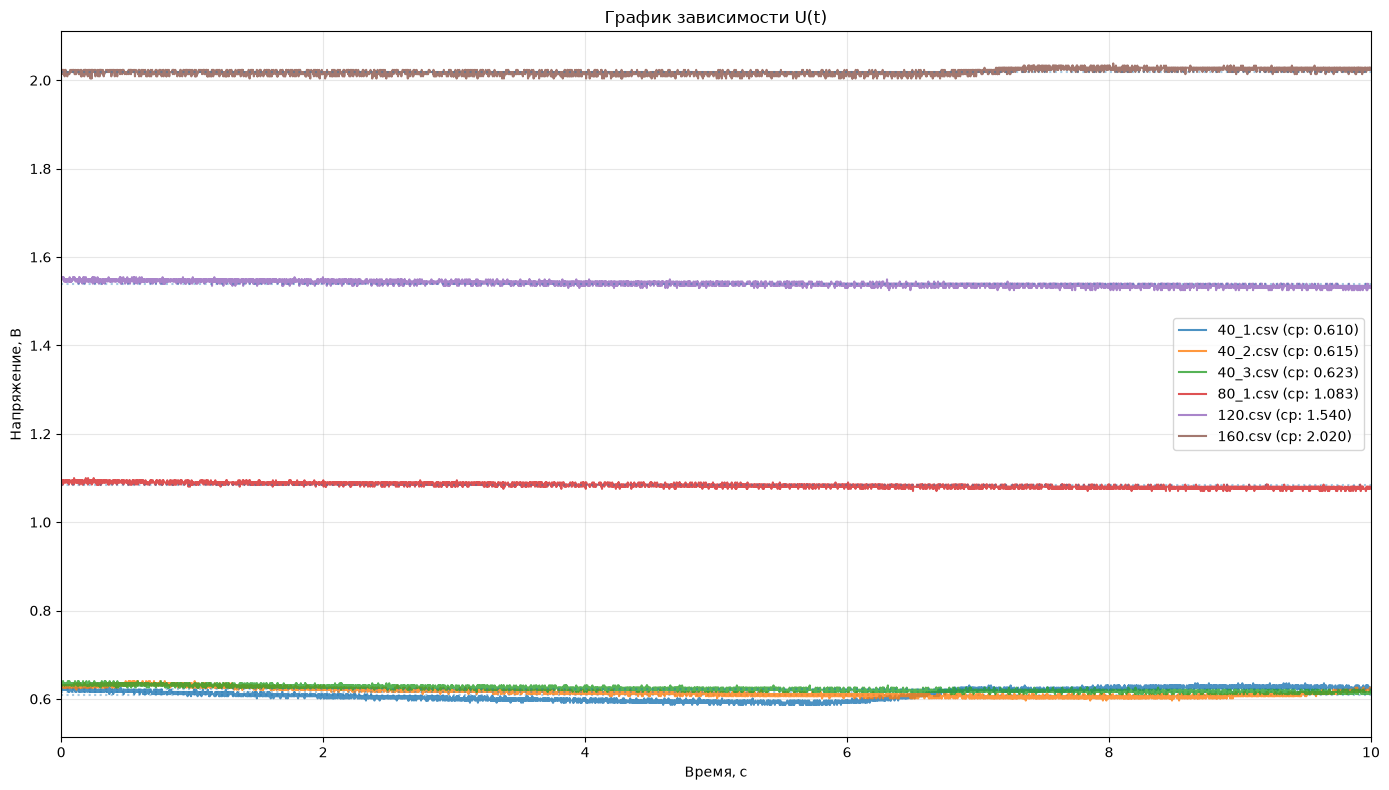

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

folder = '.'
files = ['40_1.csv', '40_2.csv', '40_3.csv', '80_1.csv', '120.csv', '160.csv']

plt.figure(figsize=(14, 8))

for file in files:
    filepath = os.path.join(folder, file)

    if not os.path.exists(filepath):
        continue

    try:
        df = pd.read_csv(filepath)
        time_raw = df.iloc[:, 0].values
        voltage_raw = df.iloc[:, 1].values

        mask = (time_raw >= 2) & (time_raw <= 6)
        time_filtered = time_raw[mask]
        voltage_filtered = voltage_raw[mask]

        t_min = time_filtered.min()
        t_max = time_filtered.max()

        time_stretched = (time_filtered - t_min) / (t_max - t_min) * 10

        mean_v = voltage_filtered.mean()

        print(f"{file:10} | Среднее: {mean_v:.4f} В")

        plt.plot(time_stretched, voltage_filtered, label=f'{file} (ср: {mean_v:.3f})', alpha=0.8)
        plt.axhline(y=mean_v, linestyle=':', alpha=0.4)

    except Exception as e:
        print(f"Ошибка с {file}: {e}")

plt.xlim(0, 10)

plt.title('График зависимости U(t)')
plt.xlabel('Время, с')
plt.ylabel('Напряжение, В')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig('U(t).png')
plt.show()

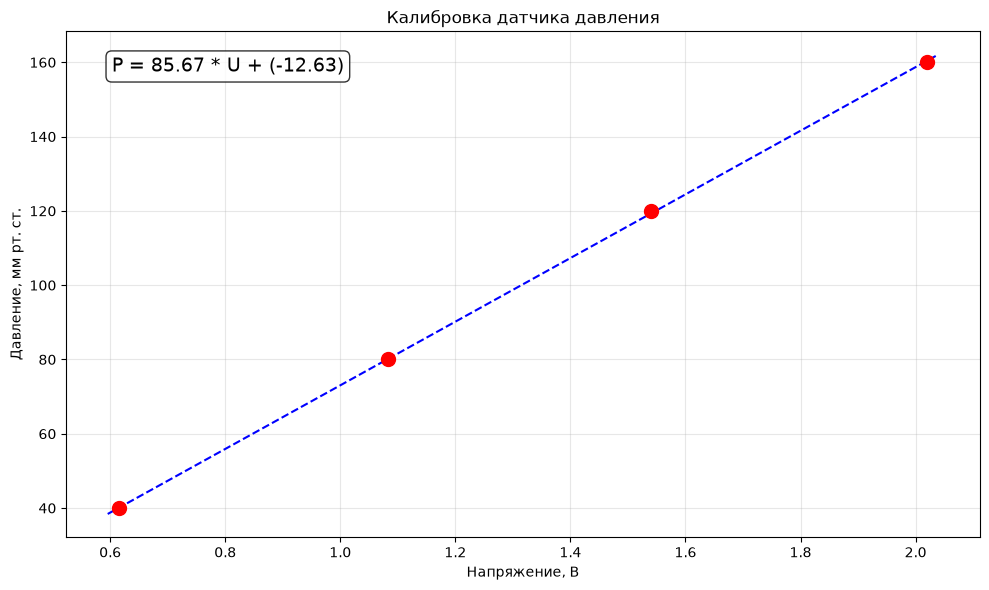

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

folder = '.'
files = ['40_1.csv', '40_2.csv', '40_3.csv', '80_1.csv', '120.csv', '160.csv']
pressures_ref = [40, 40, 40, 80, 120, 160]

pressure_data = {}

for file, p_ref in zip(files, pressures_ref):
    filepath = os.path.join(folder, file)
    if not os.path.exists(filepath):
        continue
    try:
        df = pd.read_csv(filepath)
        time_raw = df.iloc[:, 0].values
        voltage_raw = df.iloc[:, 1].values
        mask = (time_raw >= 2) & (time_raw <= 6)
        voltage_filtered = voltage_raw[mask]
        mean_v = voltage_filtered.mean()

        if p_ref not in pressure_data:
            pressure_data[p_ref] = []
        pressure_data[p_ref].append(mean_v)
    except Exception:
        pass

pressures = []
voltages = []

for p_ref, v_list in sorted(pressure_data.items()):
    avg_v = np.mean(v_list)
    pressures.append(p_ref)
    voltages.append(avg_v)

pressures = np.array(pressures)
voltages = np.array(voltages)

k, b = np.polyfit(voltages, pressures, 1)

plt.figure(figsize=(10, 6))
plt.scatter(voltages, pressures, color='red', s=100, zorder=5)

v_line = np.linspace(min(voltages) - 0.02, max(voltages) + 0.02, 100)
p_line = k * v_line + b
plt.plot(v_line, p_line, color='blue', linestyle='--')

equation_text = f"P = {k:.2f} * U + ({b:.2f})"
plt.text(0.05, 0.95, equation_text, transform=plt.gca().transAxes, fontsize=14, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.title('Калибровка датчика давления')
plt.xlabel('Напряжение, В')
plt.ylabel('Давление, мм рт. ст.')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('calibration.png')
plt.show()